# Análise de Sobrevivência em Pacientes com Insuficiência Cardíaca usando Rede Neural MLP

**Alunos:**  
Lucas Gama  
Felipe Daniel  

## Objetivo

O objetivo deste projeto é treinar uma Rede Neural Artificial do tipo **MLP (Multi-Layer Perceptron)** para prever a ocorrência de morte em pacientes com insuficiência cardíaca.

O projeto inclui:

- Pré-processamento dos dados
- Análise exploratória
- Treinamento de um modelo base
- Otimização de hiperparâmetros com Grid Search
- Validação cruzada
- Comparação entre modelos
- Experimento utilizando apenas as variáveis mais correlacionadas com o evento de morte

IA Utilizada somente para organização dos Blocos e Estruturação do texto das Markdowns

**Justificativa da Escolha do Dataset:**
Optamos pelo *Heart Failure Clinical Records Dataset* por ser um conjunto de dados do mundo real focado na área da saúde (previsão de mortalidade). Ele foi escolhido por possuir uma mistura interessante de variáveis contínuas (idade, creatinina) e categóricas (sexo, diabetes), além de não ser um dos datasets "clichês" vedados pelas regras da atividade. O tamanho do dataset (299 instâncias) exige um bom ajuste de hiperparâmetros para evitar o overfitting da rede neural.

## Importação das Bibliotecas

Nesta etapa importamos todas as bibliotecas necessárias para manipulação de dados, visualização, pré-processamento e treinamento do modelo de Machine Learning.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold

## Carregamento do Dataset

O dataset utilizado contém informações clínicas de pacientes com insuficiência cardíaca.

Cada linha representa um paciente e cada coluna representa uma característica clínica utilizada para prever a ocorrência de morte.

In [16]:
df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

df.head(10)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1
6,75.0,1,246,0,15,0,127000.00,1.2,137,1,0,10,1
7,60.0,1,315,1,60,0,454000.00,1.1,131,1,1,10,1
8,65.0,0,157,0,65,0,263358.03,1.5,138,0,0,10,1
9,80.0,1,123,0,35,1,388000.00,9.4,133,1,1,10,1


## Informações Gerais do Dataset

Nesta etapa verificamos:

- Quantidade de registros
- Tipos de dados
- Presença de valores ausentes

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


## Estatísticas Descritivas

A análise estatística permite entender melhor a distribuição das variáveis do dataset, incluindo média, desvio padrão, valores mínimos e máximos.

In [18]:
df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


## Verificação de Valores Ausentes

É importante verificar se existem valores faltantes no dataset, pois esses valores podem prejudicar o treinamento do modelo.

In [19]:
df.isnull().sum()

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

## Matriz de Correlação

A matriz de correlação mostra a relação entre as variáveis do dataset.

Valores próximos de **1** indicam forte correlação positiva, enquanto valores próximos de **-1** indicam forte correlação negativa.

Essa análise ajuda a identificar quais variáveis possuem maior relação com o evento de morte (**DEATH_EVENT**).

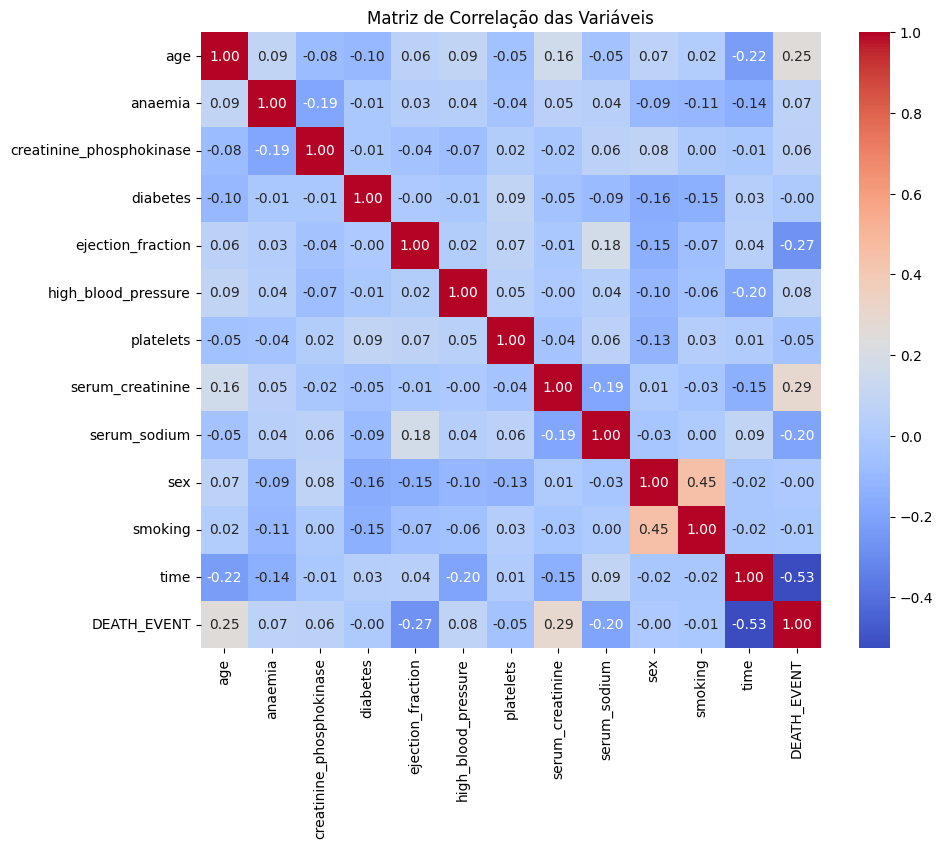

In [20]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de Correlação das Variáveis")

plt.show()

## Separação entre Variáveis de Entrada e Saída

Neste problema, o objetivo é prever a variável **DEATH_EVENT**, que indica se o paciente morreu ou não.

Assim:

- **X** representa as variáveis de entrada
- **y** representa a variável alvo

In [21]:
X = df.drop("DEATH_EVENT", axis=1)
y = df["DEATH_EVENT"]

## Divisão entre Treinamento e Teste

Os dados são divididos em:

- **80% para treinamento**
- **20% para teste**

O parâmetro `stratify=y` garante que a proporção de classes seja mantida em ambos os conjuntos.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

## Normalização dos Dados

A normalização é necessária para redes neurais, pois as variáveis do dataset possuem escalas diferentes.

Utilizamos o **StandardScaler**, que transforma os dados para terem média 0 e desvio padrão 1.

In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Treinamento do Modelo Base

Nesta etapa treinamos uma rede neural MLP simples para estabelecer um ponto de referência antes da otimização de hiperparâmetros.

In [24]:
mlp_base = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation='relu',
    solver='adam',
    max_iter=2000,
    random_state=42
)

mlp_base.fit(X_train_scaled, y_train)

y_pred_base = mlp_base.predict(X_test_scaled)

accuracy_base = accuracy_score(y_test, y_pred_base)

print("Acurácia do modelo base:", accuracy_base)

Acurácia do modelo base: 0.7333333333333333


## Matriz de Confusão

A matriz de confusão permite visualizar o desempenho do modelo de classificação.

Ela mostra:

- Quantas previsões foram corretas
- Quantos erros ocorreram
- Que tipo de erro o modelo cometeu

Os valores são organizados da seguinte forma:

- Verdadeiros Negativos (TN): pacientes corretamente classificados como sobreviventes
- Falsos Positivos (FP): pacientes classificados como mortos, mas que sobreviveram
- Falsos Negativos (FN): pacientes classificados como sobreviventes, mas que morreram
- Verdadeiros Positivos (TP): pacientes corretamente classificados como mortos

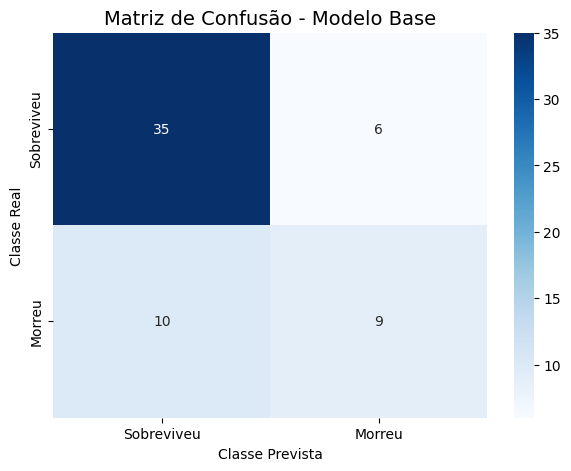

In [25]:
cm = confusion_matrix(y_test, y_pred_base)

labels = ["Sobreviveu", "Morreu"]

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Matriz de Confusão - Modelo Base", fontsize=14)
plt.xlabel("Classe Prevista")
plt.ylabel("Classe Real")

plt.show()

## Otimização de Hiperparâmetros com Grid Search

O Grid Search testa várias combinações de hiperparâmetros para encontrar a configuração que apresenta melhor desempenho.

Os hiperparâmetros testados incluem:

- Número de neurônios nas camadas ocultas
- Função de ativação
- Regularização
- Taxa de aprendizado

In [ ]:
param_grid = {

"batch_size": [32, 64, 128],

'hidden_layer_sizes': [(16), (32), (64)],

'activation': ['relu','tanh','logistic'],

'alpha': [0.0001, 0.001, 0.01],

'learning_rate_init': [0.0005, 0.001, 0.01]

}

cv_strategy = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

mlp = MLPClassifier(
    max_iter=2000,
    random_state=42,
    early_stopping=True
)

grid_search = GridSearchCV(
    mlp,
    param_grid,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Melhores parâmetros:", grid_search.best_params_)

Melhores parâmetros: {'activation': 'relu', 'alpha': 0.01, 'batch_size': 64, 'hidden_layer_sizes': 32, 'learning_rate_init': 0.01}


## Avaliação do Modelo Otimizado

In [27]:
best_model = grid_search.best_estimator_

y_pred_opt = best_model.predict(X_test_scaled)

accuracy_opt = accuracy_score(y_test, y_pred_opt)

print("Acurácia do modelo otimizado:", accuracy_opt)

Acurácia do modelo otimizado: 0.7833333333333333


## Comparação entre Modelos

Por fim, comparamos:

- Modelo base
- Modelo otimizado

In [28]:
print("Modelo Base:", accuracy_base)
print("Modelo Otimizado:", accuracy_opt)

Modelo Base: 0.7333333333333333
Modelo Otimizado: 0.7833333333333333


### Resultados da Otimização da Rede Neural

**1. O Ganho de Desempenho**
O trabalho de encontrar a configuração ideal deu resultado! Tivemos um salto exato de **5% na acurácia** (capacidade de acerto do modelo em dados novos):
* **Modelo Base (Padrão):** 73.33%
* **Modelo Otimizado:** **78.33%**

**2. A Configuração Vencedora**
O código testou várias combinações e concluiu que a melhor "receita" para essa rede neural é:

* **`hidden_layer_sizes` = 32:** Usar apenas **32 neurônios** foi o tamanho perfeito. Redes maiores provavelmente estavam apenas "decorando" os dados em vez de aprender de verdade.
* **`activation` = relu:** A função matemática padrão que melhor ajudou a rede a ligar os pontos.
* **`batch_size` = 64:** O modelo processa os dados de **64 em 64 linhas** por vez, o que trouxe mais estabilidade.
* **`learning_rate_init` = 0.01:** O modelo precisava de uma "velocidade de aprendizado" mais rápida do que a padrão para chegar ao melhor resultado.
* **`alpha` = 0.01:** Uma trava de segurança (regularização) que ajuda o modelo a focar no que importa, evitando vícios nos dados de treino.